# dalphaT Asimov Containment Closure Test

Closure check for the containment-split (contained/exiting) simultaneous fit in $\delta\alpha_T$. It reads the `Asimov_Containment` outputs of the fitter, cross-section and toy-generator runs listed in `RunConfigs/dalphaT/Asimov_Containment/Asimov_Containment_instructions.md`. The structure follows `dpT/Asimov_Containment_Studies.ipynb`.

**Binning:** truth binning is `binning_true_dalphaT_deg.txt` (4 bins: 0-65-114-151-180 deg, shared across all 4 samples). Reco binning is per channel: contained selection uses `binning_reco_dalphaT_deg_contained.txt` (14 bins), exiting selection uses `binning_reco_dalphaT_deg_exiting.txt` (10 bins), and both sidebands use their own 24-bin files. $\delta\alpha_T$ is bounded to [0, 180] deg, so unlike $\delta p_T$ none of these binnings has an overflow bin, and no bin is dropped when plotting (`remove_last_bin=False` in the scatter plots).

**`cov_bin_range` -- NOT YET VERIFIED against a dalphaT output file.** The dpT notebook slices one row short of each covariance block because the dpT binnings have an overflow bin (800 - 99999) that the category histograms drop. With no overflow bin here, each sample's block is expected to have the same width as its binning, so the full matrix is 14 + 10 + 24 + 24 = 72 rows and the slices are (0,14), (14,24), (24,48), (48,72). The check cell below compares these widths against the bin counts of the category histograms and the shape of `covarianceMatrix_TH2D` in the actual file. Run it first and edit `COV_RANGE` if it reports a mismatch.

In [1]:
try:
    from src.save_fig import save_fig
except ImportError:
    import sys, os
    sys.path.append(os.path.abspath('..'))
    from src.save_fig import save_fig

import sys
import os
sys.path.append(os.path.abspath(".."))
from src.plot_scatter import plot_scatter
from src.plot_manual_cross_section import overlay_manual_cross_section
from src.plot_fit_constraints import plot_fit_constraints
from src.plot_gundam_stacked import plot_gundam_stacked
from src.plot_GENIE_NUISANCE import overlay_genie_nuisance_xsec
from src.plot_matrices import plot_both_matrices

GUNDAM_DIR = '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM'
SELECTION_DIR = '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_Selection'

FIT_DIR  = f'{GUNDAM_DIR}/data/Fitter/dalphaT/Asimov_Containment'
XSEC_DIR = f'{GUNDAM_DIR}/data/XSection/dalphaT/Asimov_Containment'

ASIMOV_FILE  = f'{FIT_DIR}/asimov_dalphaT_containment.root'          # gundamFitter output
PREFIT_FILE  = f'{FIT_DIR}/prefit_asimov_dalphaT_containment.root'   # gundamToyGenerator --use-prefit
POSTFIT_FILE = f'{FIT_DIR}/postfit_asimov_dalphaT_containment.root'  # gundamToyGenerator --use-bf
XSEC_FILE    = f'{XSEC_DIR}/asimov_XSec_dalphaT_containment.root'    # gundamCalcXsec output

# Edges of binning_true_dalphaT_deg.txt (degrees)
TRUE_EDGES = [0.0, 65.0, 114.0, 151.0, 180.0]

# Row range of each sample inside toyGen/matrices/covarianceMatrix_TH2D, in the
# order of Configs_FitSampleSet/fitSamples_reco_dalphaT_deg_containment.yaml.
# No overflow bin in any dalphaT binning, so block width = number of bins.
SAMPLES = {
    'selection_contained': 'selection_reco_dalphaT_contained',
    'selection_exiting':   'selection_reco_dalphaT_exiting',
    'sideband_contained':  'sideband_reco_dalphaT_contained',
    'sideband_exiting':    'sideband_reco_dalphaT_exiting',
}
COV_RANGE = {
    'selection_contained': (0, 14),
    'selection_exiting':   (14, 24),
    'sideband_contained':  (24, 48),
    'sideband_exiting':    (48, 72),
}

POT = r'NuMI MC 7.10 $\times 10^{20}$ POT'

## Binning Sanity Check

Compares the expected covariance block widths in `COV_RANGE` with the actual contents of the pre-fit toy-generator file. Every line should end in `OK`.

In [2]:
import uproot

f_pre = uproot.open(PREFIT_FILE)
cov_full = f_pre['toyGen/matrices/covarianceMatrix_TH2D'].values()
expected_rows = max(hi for _, hi in COV_RANGE.values())
print(f'covarianceMatrix_TH2D shape: {cov_full.shape}  (expected {expected_rows} x {expected_rows})  ->',
      'OK' if cov_full.shape == (expected_rows, expected_rows) else 'MISMATCH')

for key, sample in SAMPLES.items():
    lo, hi = COV_RANGE[key]
    nbins = None
    for cat in range(11):
        path = f'toyGen/plots/histograms/{sample} (pre-fit)/reco_dalphaT_deg/category/{cat}/MC_TH1D'
        try:
            nbins = len(f_pre[path].values())
            break
        except KeyError:
            continue
    status = 'OK' if nbins == hi - lo else 'MISMATCH'
    print(f'{sample:<36} category-histogram bins: {nbins}  |  COV_RANGE width: {hi - lo}  ->  {status}')

covarianceMatrix_TH2D shape: (72, 72)  (expected 72 x 72)  -> OK
selection_reco_dalphaT_contained     category-histogram bins: 14  |  COV_RANGE width: 14  ->  OK
selection_reco_dalphaT_exiting       category-histogram bins: 10  |  COV_RANGE width: 10  ->  OK
sideband_reco_dalphaT_contained      category-histogram bins: 24  |  COV_RANGE width: 24  ->  OK
sideband_reco_dalphaT_exiting        category-histogram bins: 24  |  COV_RANGE width: 24  ->  OK


## Selection - Contained

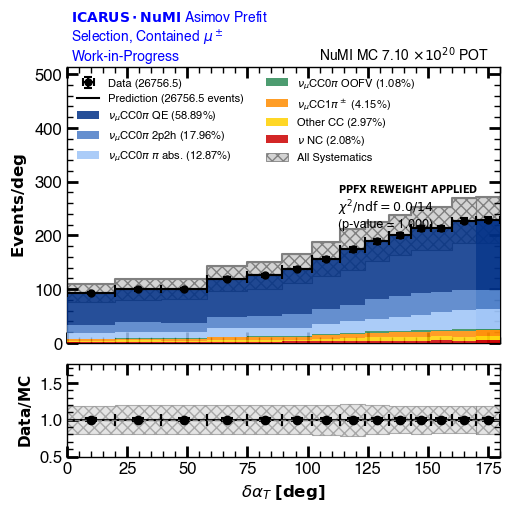

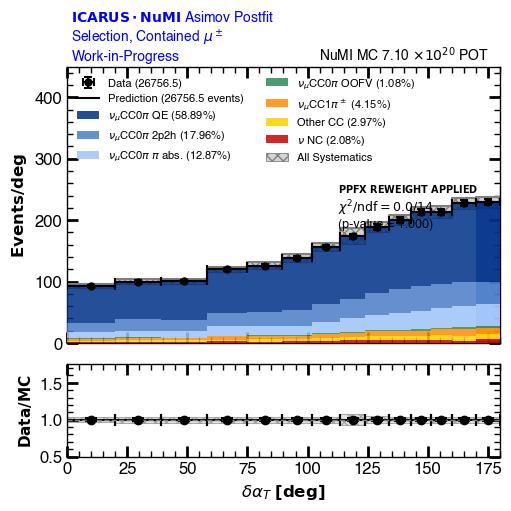

In [3]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=PREFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['selection_contained'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['selection_contained'],
    fit_type='pre-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + r'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dalphaT/Asimov_Containment/Prefits', save_name='prefit_dalphaT_selection_contained',
    pot=POT,
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=POSTFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['selection_contained'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['selection_contained'],
    fit_type='post-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + r'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=POT,
    save_dir=r'../Plots/dalphaT/Asimov_Containment/Postfits', save_name='postfit_dalphaT_selection_contained'
)

## Selection - Exiting

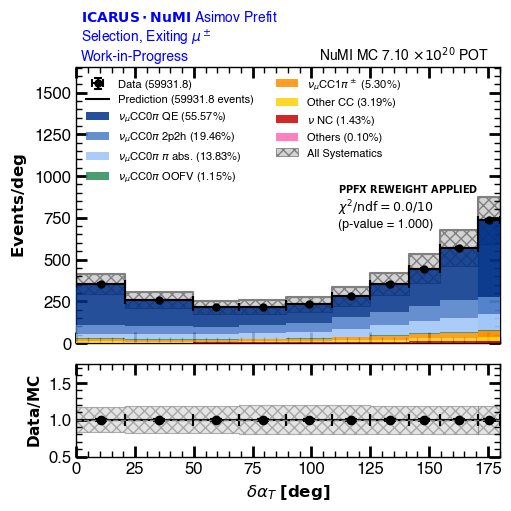

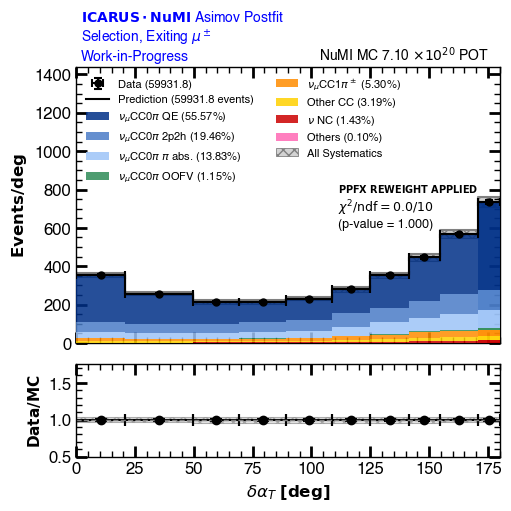

In [4]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=PREFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['selection_exiting'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['selection_exiting'],
    fit_type='pre-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + r'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dalphaT/Asimov_Containment/Prefits', save_name='prefit_dalphaT_selection_exiting',
    pot=POT,
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=POSTFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['selection_exiting'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['selection_exiting'],
    fit_type='post-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + r'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=POT,
    save_dir=r'../Plots/dalphaT/Asimov_Containment/Postfits', save_name='postfit_dalphaT_selection_exiting'
)

## Sideband - Contained

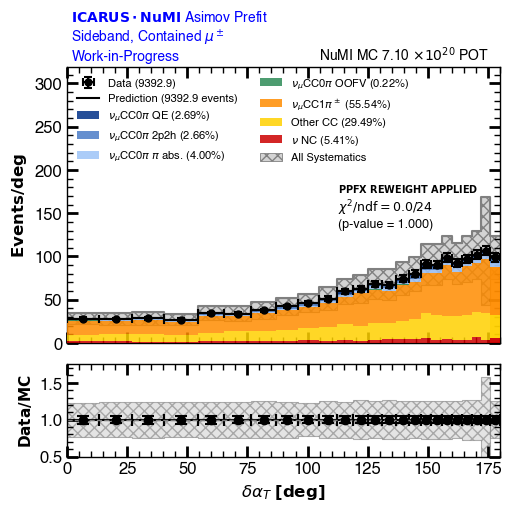

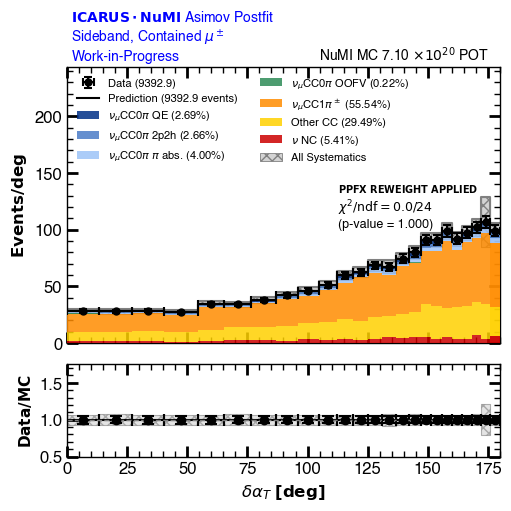

In [5]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=PREFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['sideband_contained'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['sideband_contained'],
    fit_type='pre-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + r'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dalphaT/Asimov_Containment/Prefits', save_name='prefit_dalphaT_sideband_contained',
    pot=POT,
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=POSTFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['sideband_contained'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['sideband_contained'],
    fit_type='post-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + r'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=POT,
    save_dir=r'../Plots/dalphaT/Asimov_Containment/Postfits', save_name='postfit_dalphaT_sideband_contained'
)

## Sideband - Exiting

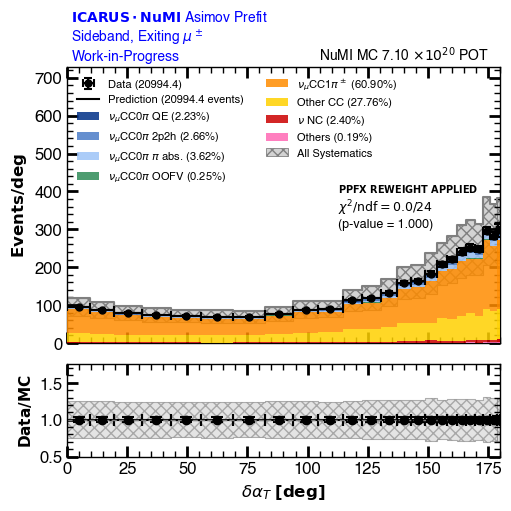

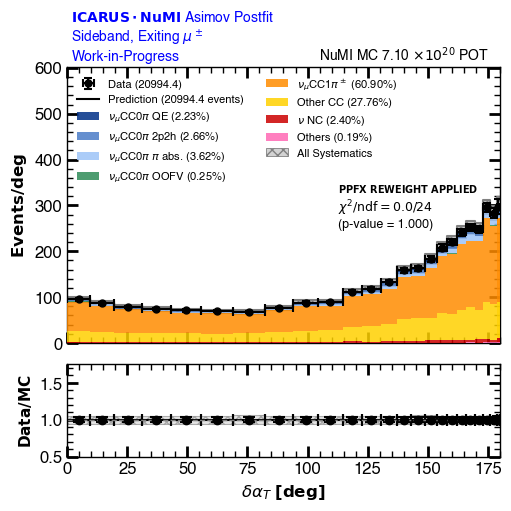

In [6]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=PREFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['sideband_exiting'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['sideband_exiting'],
    fit_type='pre-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + r'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dalphaT/Asimov_Containment/Prefits', save_name='prefit_dalphaT_sideband_exiting',
    pot=POT,
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=POSTFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['sideband_exiting'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['sideband_exiting'],
    fit_type='post-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + r'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=POT,
    save_dir=r'../Plots/dalphaT/Asimov_Containment/Postfits', save_name='postfit_dalphaT_sideband_exiting'
)

## Cross-Section Extraction

Extracted from `asimov_XSec_dalphaT_containment.root` (CalcXsec run on the containment-fit output). It uses the true-level `True_dalphaT_XS` sample with 4 truth bins, which the reco-level containment split does not change. Units are cm$^2$/deg/Ar. Because $\delta\alpha_T$ is in degrees there is no MeV to GeV conversion: the GUNDAM histogram, the manual calculation and the GENIE overlay are all scaled by $10^{40}$ directly. The truth binning has no overflow bin, so `remove_last_bin=False`.

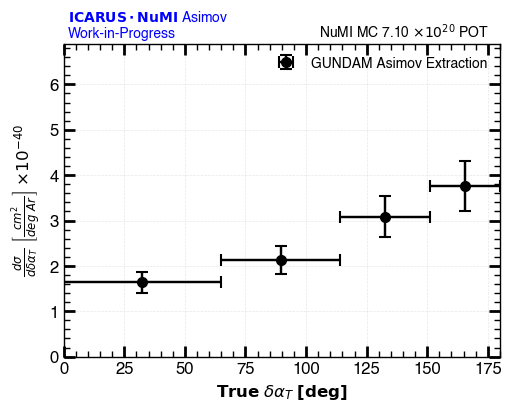

In [32]:
# Create the scatter plot and get the raw values
fig_xs, ax_xs, xsec_extracted_raw, xsec_extracted_errors_raw = plot_scatter(
    filename=XSEC_FILE,
    is_cross_section=True,
    hist_path="calcXsec/histograms/True_dalphaT_XS_TH1D;1",
    xlabel=r'$\mathbf{True}$ $\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\frac{d\sigma}{d\delta\alpha_T}$ $\left[\frac{cm^2}{deg\ Ar}\right]$ $\times 10^{-40}$',
    bin_edges_labels=TRUE_EDGES,
    remove_last_bin=False,
    is_y_errors=True,
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    label="GUNDAM Asimov Extraction",
    pot=POT,
    scaling_power_of_10=1e40
)

save_fig(fig_xs, r'../Plots/dalphaT/Asimov_Containment/XSection', 'dalphaT_XS')


Signal Events and Cross-Section per True Bin
Bin Range (MeV/c)         N_Signal     Bin Width (MeV)    σ (x10^-40 cm²/GeV)
------------------------------------------------------------------------------------------
     0 - 65     MeV/c    27626        65                 1.639003e+00
    65 - 114    MeV/c    27060        49                 2.129729e+00
   114 - 151    MeV/c    29585        37                 3.086042e+00
   151 - 180    MeV/c    28198        29                 3.760304e+00
------------------------------------------------------------------------------------------
Total                     112469


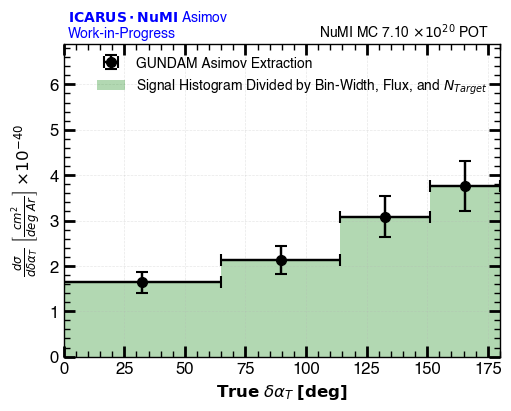

In [8]:
bins_deg = [(0, 65), (65, 114), (114, 151), (151, 180)]
# Overlay manual calculation -- unaffected by the containment split (true-level signal tree, no containment cut).
# overlay_manual_cross_section always multiplies by 1e3 (MeV -> GeV). That factor does not apply to a
# variable in degrees, so scaling_power_of_10 is 1e37 (not 1e40) to give 1e3 * 1e37 = 1e40 in cm^2/deg.
# energy_conversion=False keeps the bar positions and widths in degrees.
fig, ax, xs = overlay_manual_cross_section(
    fig=fig_xs,
    ax=ax_xs,
    signal_tree_path="events/full/signal",
    root_file_path=f"{SELECTION_DIR}/data/icarus_numi_numu_mc_onbeam_offbeam_syst_gundam.root",
    bins_mev=bins_deg,
    n_targets=4.721444e30,
    flux=5.1915e11,
    color='green',
    marker='s',
    label=r'Signal Histogram Divided by Bin-Width, Flux, and $N_{Target}$',
    variable_name="true_dalphaT_deg",
    scaling_power_of_10=1e37,
    energy_conversion=False
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment/XSection', 'dalphaT_XS_wSignal')
display(fig)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaalphaT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 65.0000           1.555173e+00
  65.0000 – 114.0000           2.155479e+00
  114.0000 – 151.0000           3.327037e+00
  151.0000 – 180.0000           3.964480e+00

χ² / Ndof = 0.6 / 4 = 0.144
p-value = 0.966


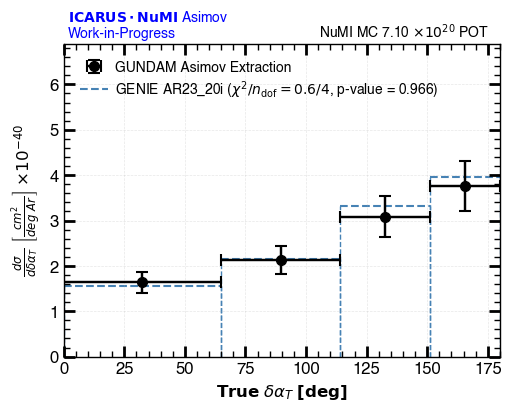

In [33]:
# Overlay GENIE with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir=f"{GUNDAM_DIR}/data/Generators/GENIE/fhc_Nu14",
    nuisance_file_dir_numubar=f"{GUNDAM_DIR}/data/Generators/GENIE/fhc_Nu-14",
    bin_edges=TRUE_EDGES,
    nuisance_var='ICARUS_1muNp0pi_deltaalphaT',   # degrees in the NUISANCE flat tree
    scaling_power_of_10=1e40,                     # per degree, same units as the GUNDAM points above
    label='GENIE AR23_20i',
    extracted_xsec=xsec_extracted,
    extracted_xsec_errors=xsec_extracted_errors,
    add_ratio=False,
    draw_extracted_ratio=False,
)

save_fig(fig_genie, r'../Plots/dalphaT/Asimov_Containment/XSection', 'dalphaT_XS_wGENIE')
display(fig_genie)

## Template Parameter Post-fit Values

One set of 4 template parameters, shared across all four samples in the joint fit -- not split by containment.

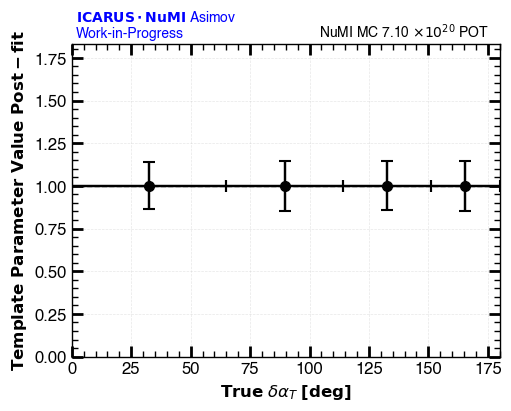

In [10]:
fig_template, ax_template, dummy, dummy2 = plot_scatter(
        filename=ASIMOV_FILE,
        is_cross_section = False,
        hist_path="FitterEngine/postFit/Hesse/errors/Template Parameter true_dalphaT_deg/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{True}$ $\delta\alpha_T$ $\mathbf{[deg]}$',
        ylabel='$\mathbf{Template\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=TRUE_EDGES,
        remove_last_bin=False,   # no overflow bin in binning_true_dalphaT_deg.txt
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
        label=None,
        hline_nuisance=True,
        pot=POT
)
save_fig(fig_template, r'../Plots/dalphaT/Asimov_Containment/TemplateParameters', 'dalphaT')

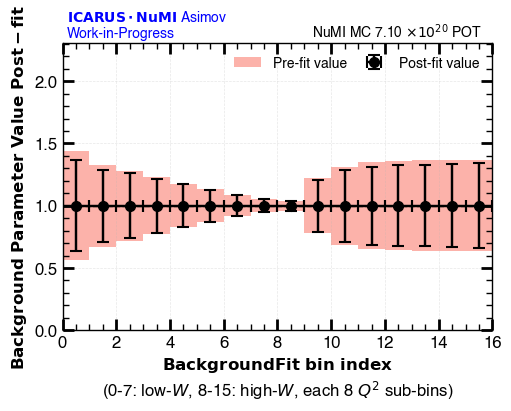

In [11]:
fig_bkg_template, ax_bkg_template, dummy, dummy2 = plot_scatter(
        filename=ASIMOV_FILE,
        is_cross_section=False,
        hist_path="FitterEngine/postFit/Hesse/errors/BackgroundFit true_generator_w binbybin/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{BackgroundFit\ bin\ index}$' + '\n' + r'(0-7: low-$W$, 8-15: high-$W$, each 8 $Q^2$ sub-bins)',
        ylabel=r'$\mathbf{Background\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=list(range(17)),   # 17 edges -> 16 unit-width bins, matches the 16 real bins exactly
        remove_last_bin=False,               # there is no overflow bin in this scheme -- don't drop bin 15
        is_y_errors=True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
        hline_nuisance=True,
        pot=POT,
        show_prior=True,
)
save_fig(fig_bkg_template, r'../Plots/dalphaT/Asimov_Containment/BackgroundFitParameters', 'dalphaT')

## Nuisance Parameter Constraints

Pre-fit/post-fit constraint plots for the interaction-model, flux, and detector systematics. These dial sets do not depend on the observable or on the reco-level split (`applyOnDataSets` is keyed by dataset name, not fitSample name), so this is one set of plots for the whole joint fit. The G4 sets are the same three used in the dpT fit (proton, $\pi^+$, $\pi^-$), binned in the true leading-proton momentum and leading-pion kinetic energy rather than in the observable, so they are shared by all observables and are no longer split by muon containment.

Number of parameters: 52


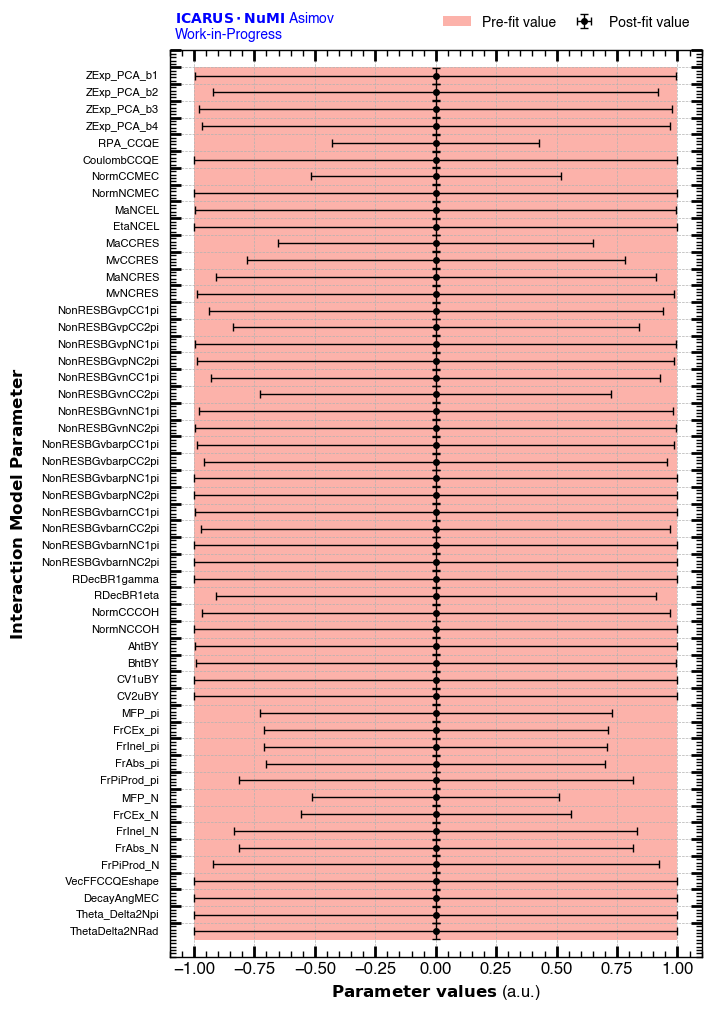

In [12]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 10),
    y_label=r'$\mathbf{Interaction\ Model\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Cross section Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment/NuisanceParameters', 'dalphaT_InteractionModel')

Number of parameters: 27


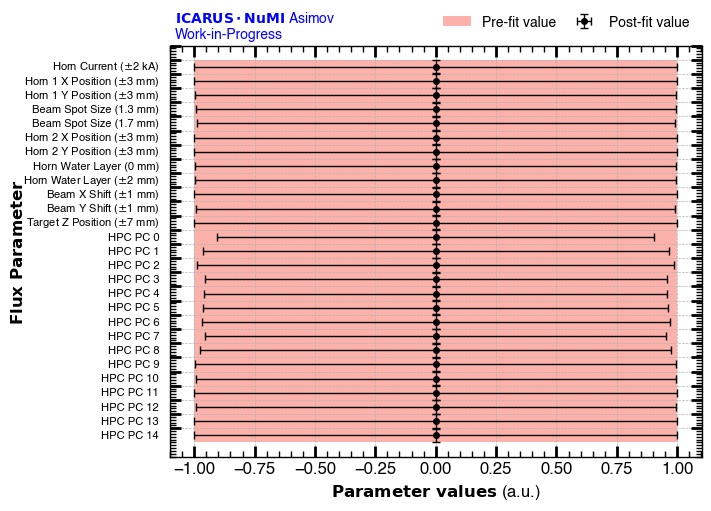

In [13]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 5),
    y_label=r'$\mathbf{Flux\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Multisigma Flux Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment/NuisanceParameters', 'dalphaT_Flux')

Number of parameters: 9


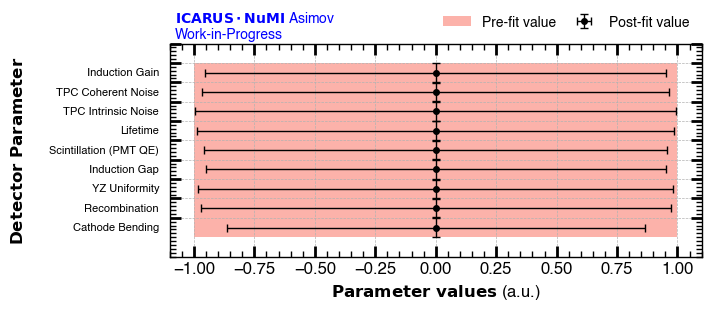

In [14]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 3),
    y_label=r'$\mathbf{Detector\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Detector Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment/NuisanceParameters', 'dalphaT_Detector')

In [ ]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 5),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment/NuisanceParameters', 'dalphaT_G4_Proton')

In [ ]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 5),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment/NuisanceParameters', 'dalphaT_G4_Piplus')

In [ ]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 5),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment/NuisanceParameters', 'dalphaT_G4_Piminus')

## Covariance / Correlation Matrices

Per-systematic-block matrices (interaction model, flux, detector, G4) -- these are among the nuisance parameters themselves, not among reco bins, so `bin_range` is left at its default (full block). Not to be confused with the reco-bin covariance used inside `plot_gundam_stacked`'s chi2 calculation, which is a different matrix (`toyGen/matrices/covarianceMatrix_TH2D`).

Full matrix size: 52×52


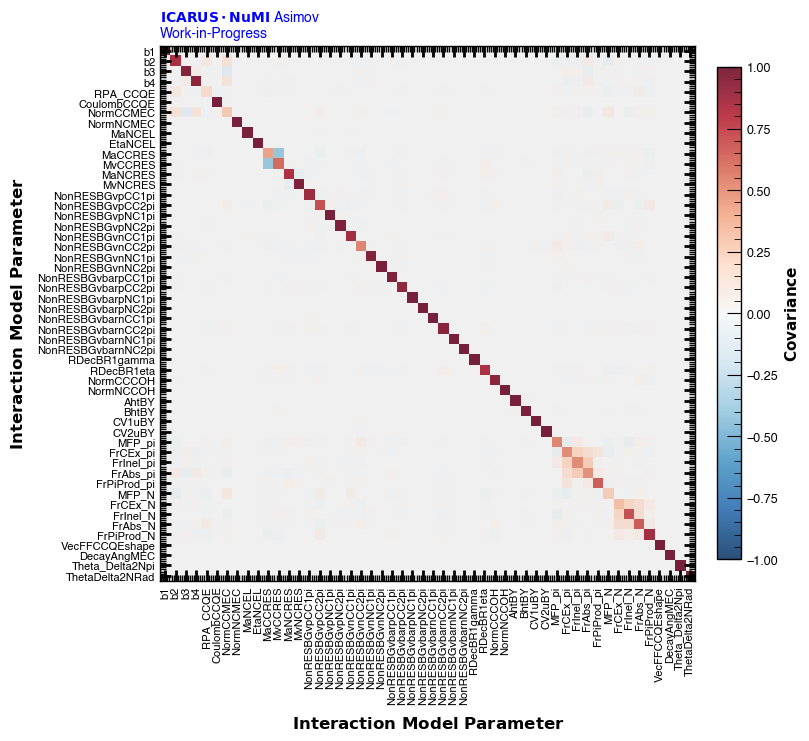

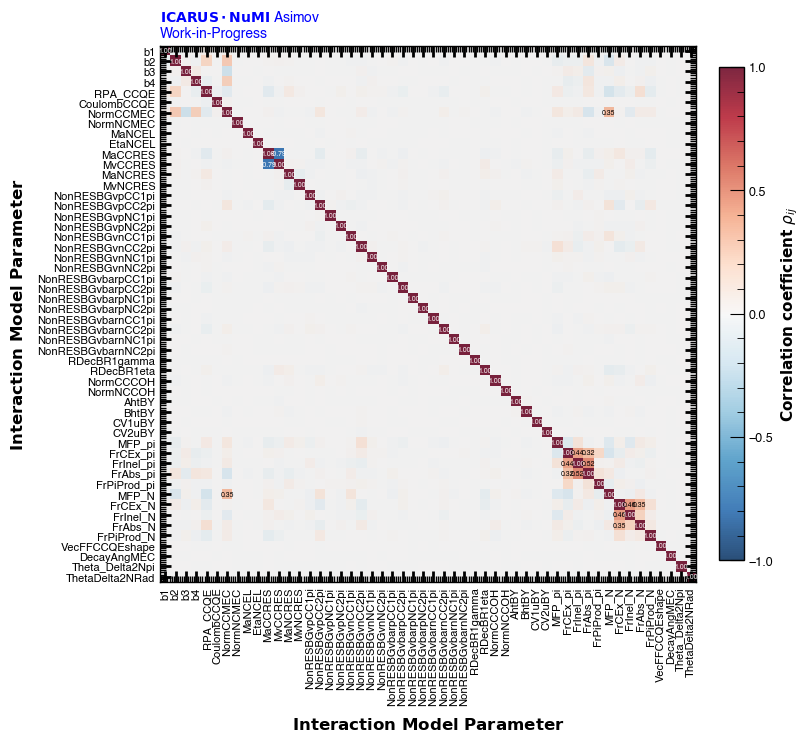

In [21]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(8, 20),
    label_name=r"$\mathbf{Interaction\ Model\ Parameter}$",
    cov_path  = f"{BASE}/Cross section Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Cross section Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment/Postfits', 'xsec_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment/Postfits', 'xsec_param_correlation')

Full matrix size: 27×27


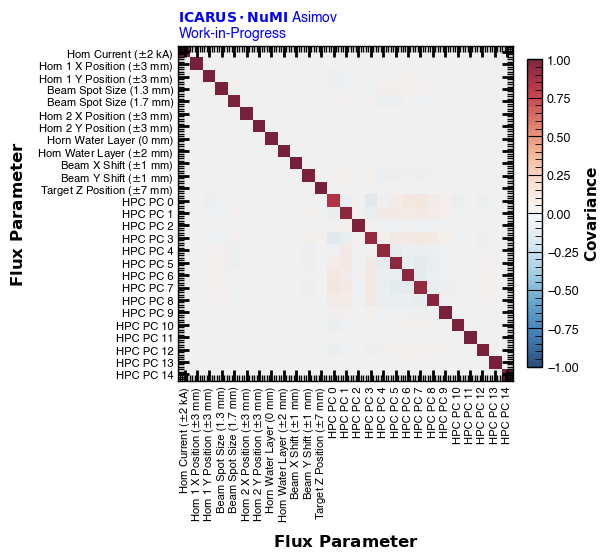

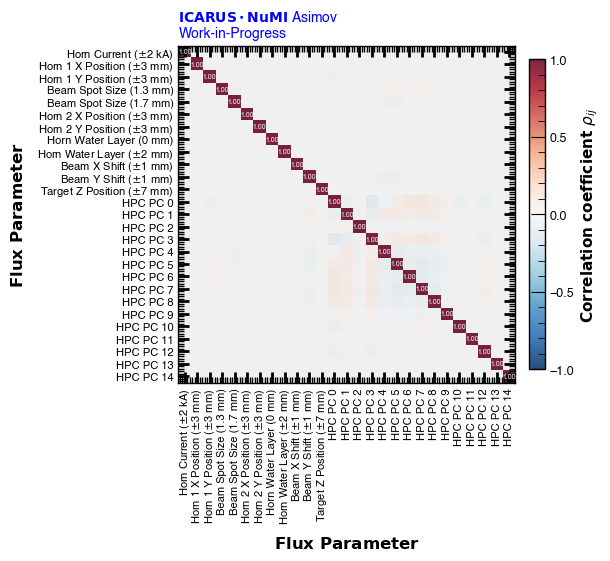

In [22]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 15),
    label_name=r"$\mathbf{Flux\ Parameter}$",
    cov_path  = f"{BASE}/Multisigma Flux Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Multisigma Flux Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment/Postfits', 'flux_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment/Postfits', 'flux_param_correlation')

Full matrix size: 9×9


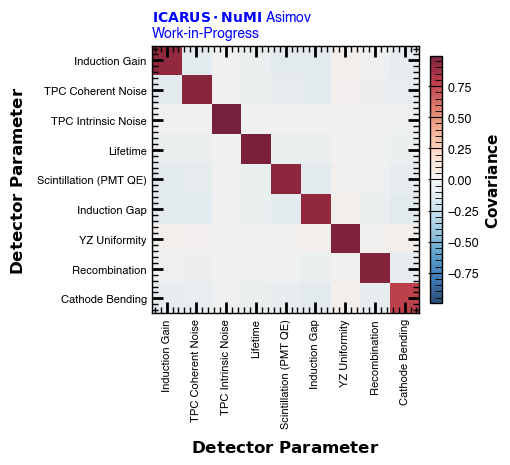

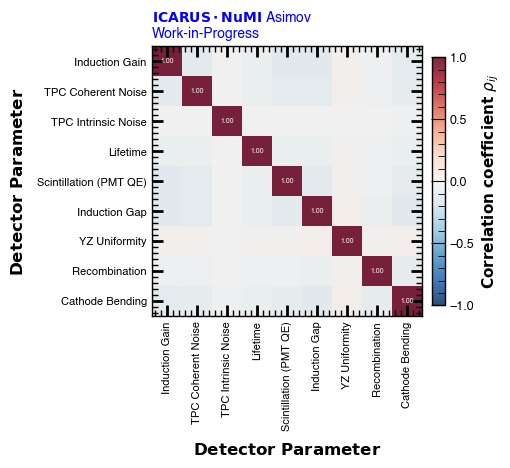

In [23]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(5, 15),
    label_name=r"$\mathbf{Detector\ Parameter}$",
    cov_path  = f"{BASE}/Detector Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Detector Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment/Postfits', 'detector_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment/Postfits', 'detector_param_correlation')

In [ ]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 11),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment/Postfits', 'g4_proton_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment/Postfits', 'g4_proton_param_correlation')

In [ ]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 11),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment/Postfits', 'g4_piplus_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment/Postfits', 'g4_piplus_param_correlation')

In [ ]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 11),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment/Postfits', 'g4_piminus_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment/Postfits', 'g4_piminus_param_correlation')

## Full Covariance / Correlation Matrix (All Systematics + Template Parameters)

Single matrix over every free parameter in the fit -- template, background-fit, cross-section, flux, detector, and all six G4 groups -- read from the fitter's own postfit Hessian block (`FitterEngine/postFit/Hesse/hessian`), not the per-group `errors` blocks the cells above use. `annotate` is left off here since the matrix is too large for per-cell values to be legible.

In [ ]:
BASE_ALL = "FitterEngine/postFit/Hesse/hessian"
GROUP_ORDER = [
    "Template Parameter true_dalphaT_deg",
    "Cross section Systematics",
    "Multisigma Flux Systematics",
    "Detector Systematics",
    "G4 Proton Fate",
    "G4 Piplus Fate",
    "G4 Piminus Fate",
    "BackgroundFit true_generator_w binbybin",
]
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(30, 24),
    cov_path  = f"{BASE_ALL}/postfitCovariance_TH2D;1",
    corr_path = f"{BASE_ALL}/postfitCorrelation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=False,
    group_order=GROUP_ORDER,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment/Postfits', 'all_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment/Postfits', 'all_param_correlation')


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaalphaT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 65.0000           5.401409e-01
  65.0000 – 114.0000           7.181958e-01
  114.0000 – 151.0000           9.114462e-01
  151.0000 – 180.0000           9.239424e-01

GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaalphaT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 65.0000           1.097027e+00
  65.0000 – 114.0000           1.557477e+00
  114.0000 – 151.0000           2.348653e+00
  151.0000 – 180.0000           2.564015e+00

GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaalphaT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 65.0000           1.541400e+00
  65.0000 – 114.0000           2.133842e+00
  114.0000 – 151.0000       

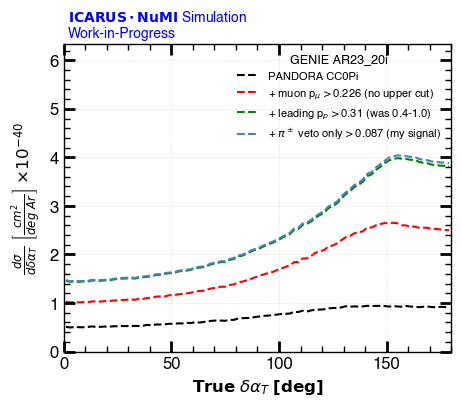

In [2]:
# GENIE cross section: signal definition morphing from Howard's to mine
import matplotlib.pyplot as plt
# Same axes/format as the other cross-section plots (plot_scatter), with the
# GUNDAM points removed so only the GENIE curves are shown.
fig_mor, ax_mor, _, _ = plot_scatter(
    filename=XSEC_FILE,
    is_cross_section=True,
    hist_path="calcXsec/histograms/True_dalphaT_XS_TH1D;1",
    xlabel=r'$\mathbf{True}$ $\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\frac{d\sigma}{d\delta\alpha_T}$ $\left[\frac{cm^2}{deg\ Ar}\right]$ $\times 10^{-40}$',
    bin_edges_labels=TRUE_EDGES,
    remove_last_bin=False,
    is_y_errors=True,
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Simulation' + '\n' + 'Work-in-Progress',
    label=None,
    pot='',
    scaling_power_of_10=1e40
)
# drop the GUNDAM extraction, keep the frame, ticks, title and labels
for art in list(ax_mor.lines) + list(ax_mor.collections):
    art.remove()
ax_mor.containers.clear()

steps = [
    ('ICARUS_1muNp0pi_IsSignal_Howard',        "PANDORA CC0Pi",                      'black'),
    ('ICARUS_1muNp0pi_IsSignal_muonChanged',   "+ muon p$_\\mu$ > 0.226 (no upper cut)", 'red'),
    ('ICARUS_1muNp0pi_IsSignal_protonChanged', "+ leading p$_p$ > 0.31 (was 0.4-1.0)",  'green'),
    ('ICARUS_1muNp0pi_IsSignal',               "+ $\\pi^\\pm$ veto only > 0.087 (my signal)", 'steelblue'),
]

# Line styles in draw order. Overlapping models stay distinguishable because the first is the
# thickest and solid, and each later one is thinner and drawn on top with a different dash pattern.
LINE_STYLES = [
    dict(linewidth=3.6, linestyle='-',             zorder=1),   # baseline: thick, solid, underneath
    dict(linewidth=2.6, linestyle=(0, (2.5, 1.5)), zorder=2),   # dashed
    dict(linewidth=1.9, linestyle=(0, (1.0, 1.2)), zorder=3),   # dotted
    dict(linewidth=1.1, linestyle='-',             zorder=4),   # thin solid on top
]

ymax = 0
for (branch, lab, col), sty in zip(steps, LINE_STYLES):
    _, _, xs, _ = overlay_genie_nuisance_xsec(
        fig_mor, ax_mor,
        nuisance_file_dir=f"{GUNDAM_DIR}/data/Generators/GENIE/fhc_Nu14",
        nuisance_file_dir_numubar=f"{GUNDAM_DIR}/data/Generators/GENIE/fhc_Nu-14",
        bin_edges=TRUE_EDGES,
        nuisance_var='ICARUS_1muNp0pi_deltaalphaT',
        signal_expr=f'{branch} == True',
        scaling_power_of_10=1e40,
        label=lab, color=col,
        **sty,
        finer_binning=True,    # smooth curve on a fine grid instead of steps on the analysis bins
        n_fine_bins=90,       # 0 to 180 deg in 2 deg bins
        add_ratio=False,
    )
    ymax = max(ymax, float(max(xs)))

new_ymax = ymax * 1.6
ax_mor.set_ylim(0, new_ymax)

# plot_scatter placed the title/POT text above the *old* y-range; move them
# to just above the frame of the new one
for t in ax_mor.texts:
    t.set_position((t.get_position()[0], new_ymax + 0.01 * new_ymax))

# legend: steps in order, inside the frame (upper right, where the curves are low)
handles, labels = ax_mor.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
order = [lab for _, lab, _ in steps]
ax_mor.legend([by_label[o] for o in order], order, loc='upper right',
              handlelength=3.5, fontsize=8, title='GENIE AR23_20i', title_fontsize=9, framealpha=0.8)

save_fig(fig_mor, r'../Plots/dalphaT/Asimov_Containment/XSection', 'dalphaT_XS_GENIE_signal_morphing')
plt.close(fig_mor)   # avoid the inline backend drawing the figure a second time
display(fig_mor)